# Perbandingan Klasifikasi: Naive Bayes vs SVM vs KNN vs XGBoost
**Dataset PBL: Lettuce (hidroponik)** - Kelompok 5, Pembelajaran Mesin

Tujuan: menentukan metode klasifikasi terbaik untuk memprediksi **tahap pertumbuhan selada (Awal / Tengah / Akhir)** dari kondisi lingkungan, dengan **praproses, split, validasi silang, dan tuning yang identik** untuk semua model (apple-to-apple).

## Fundamental dari jurnal rujukan
| Jurnal | Relevansi untuk eksperimen ini |
|---|---|
| Lauguico et al. (2020), *Comparative Analysis of ML Algorithms ... Lettuce Growth Stage Classification*, IJESD 11(9) | Membandingkan LR, KNN, dan Linear SVM untuk 3 tahap pertumbuhan selada. Fitur **distandardisasi**, model dibandingkan dengan **cross-validation** lalu **dituning**; KNN terbaik (CV mean accuracy 87,06%, akurasi uji ~91%). Kami meniru alurnya: standardisasi, CV, tuning hiperparameter, lalu metrik accuracy/precision/F1. |
| AlBroomi et al. (2026), *ML-Based Prediction of Lettuce Growth Utilising Online Environmental Datasets*, J. Phys.: Conf. Ser. 3191 | Merangkum bahwa SVM, KNN, Gaussian NB, dan XGBoost lazim dipakai pada prediksi pertumbuhan selada; menekankan **pembersihan data (outlier, missing value), normalisasi**, dan bahwa **tuning hiperparameter** meningkatkan model boosting secara nyata. |
| Rizkiana et al. (2021), *Plant growth prediction model for lettuce ... using ANN*, IOP EES 733 | Memakai **4 variabel lingkungan** sebagai input dan **normalisasi data**; membenarkan pemilihan 4 fitur lingkungan (suhu, kelembapan, TDS, pH) sebagai prediktor. |

## Fundamental singkat tiap metode
- **Naive Bayes (Gaussian):** Teorema Bayes dengan asumsi fitur saling independen; tiap fitur numerik dimodelkan sebagai distribusi normal per kelas. Cepat, tetapi asumsi independensi sering dilanggar pada data sensor.
- **SVM (kernel RBF):** mencari hyperplane dengan margin maksimum; kernel RBF menangani batas kelas non-linear. Sensitif terhadap skala fitur (C dan gamma perlu dituning).
- **KNN:** memprediksi kelas dari mayoritas k tetangga terdekat; non-parametrik, sensitif terhadap skala dan nilai k.
- **XGBoost:** gradient boosting dari banyak pohon keputusan dangkal; menangkap interaksi non-linear antar-fitur, tetapi punya banyak hiperparameter.

## Prinsip apple-to-apple
Fitur sama (4 fitur lingkungan), split train/test **berdasarkan Plant_ID** yang sama, kuantil kelas dihitung hanya dari data latih, pipeline sama (imputasi median -> StandardScaler -> model), CV sama (StratifiedGroupKFold 5-lipat, grup = Plant_ID), tuning GridSearchCV dengan skor sama (F1 macro), `random_state=42`.

In [17]:
!pip -q install xgboost

In [18]:
import os, time, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, GroupShuffleSplit, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
import sklearn, xgboost
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid')
SEED = 42
print('scikit-learn', sklearn.__version__, '| xgboost', xgboost.__version__)

scikit-learn 1.6.1 | xgboost 3.4.1


## 1. Memuat data & split berdasarkan tanaman (Plant_ID)
File latih (`lettuce_dataset_training.csv`) tidak punya header, jadi nama kolom diberikan manual. Jika `lettuce_dataset_updated.csv` (data penuh) tersedia, data uji = tanaman yang **tidak** ada di file latih. Split per tanaman mencegah kebocoran data (hari-hari berurutan dari tanaman yang sama tidak boleh ada di latih sekaligus uji).

In [19]:
COLS = ['Plant_ID','Date','Temperature (°C)','Humidity (%)','TDS Value (ppm)','pH Level','Growth Days','Temperature (F)','Humidity']
FEATURES = ['Temperature (°C)','Humidity (%)','TDS Value (ppm)','pH Level']
PATH_TRAIN, PATH_FULL = 'lettuce_dataset_training.csv', 'lettuce_dataset_updated.csv'

tr = pd.read_csv(PATH_TRAIN, encoding='latin1', header=None, names=COLS)
if not str(tr.iloc[0,0]).strip().isdigit(): tr = tr.iloc[1:].reset_index(drop=True)   # buang baris header bila ada
for c in COLS[2:7]+COLS[7:]: tr[c] = pd.to_numeric(tr[c], errors='coerce')
tr['Plant_ID'] = tr['Plant_ID'].astype(int)

if os.path.exists(PATH_FULL):
    full = pd.read_csv(PATH_FULL, encoding='latin1'); full.columns = COLS
    train_ids = set(tr['Plant_ID'])
    df_tr = full[full['Plant_ID'].isin(train_ids)].reset_index(drop=True)
    df_te = full[~full['Plant_ID'].isin(train_ids)].reset_index(drop=True)
    SPLIT_INFO = 'train = file latih; test = tanaman lain pada data penuh'
else:
    gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=SEED)
    i_tr, i_te = next(gss.split(tr, groups=tr['Plant_ID']))
    df_tr, df_te = tr.iloc[i_tr].reset_index(drop=True), tr.iloc[i_te].reset_index(drop=True)
    SPLIT_INFO = 'PERINGATAN: data penuh tidak ditemukan; 70/30 per Plant_ID dari file latih saja'
print(SPLIT_INFO)
print(f'Latih: {len(df_tr)} baris / {df_tr.Plant_ID.nunique()} tanaman | Uji: {len(df_te)} baris / {df_te.Plant_ID.nunique()} tanaman')
print('Missing (fitur):', int(df_tr[FEATURES].isna().sum().sum()), '| Duplikat:', int(df_tr.duplicated().sum()))

train = file latih; test = tanaman lain pada data penuh
Latih: 2213 baris / 49 tanaman | Uji: 956 baris / 21 tanaman
Missing (fitur): 0 | Duplikat: 0


## 2. Target kelas & praproses bersama
Target `Growth Days` dibagi 3 kelas (**Awal / Tengah / Akhir**) berdasarkan kuantil data **latih saja**, lalu batas yang sama dipakai untuk data uji. `Growth Days` tidak dipakai sebagai fitur (agar tidak bocor ke target).

Batas kuantil (hari): [16. 31.]
             latih  uji
Growth Days            
Awal           784  336
Tengah         735  315
Akhir          694  305
Baseline akurasi (kelas mayoritas): 0.3515


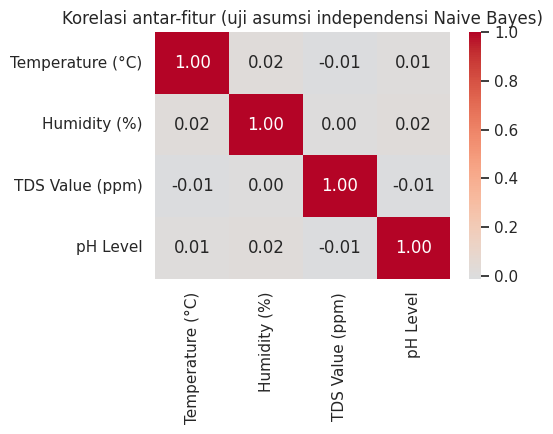

In [20]:
q = df_tr['Growth Days'].quantile([1/3, 2/3]).values
NAMA = ['Awal','Tengah','Akhir']
def to_class(s): return pd.cut(s, [-np.inf, q[0], q[1], np.inf], labels=NAMA).astype(str)
le = LabelEncoder().fit(NAMA);
ytr_s, yte_s = to_class(df_tr['Growth Days']), to_class(df_te['Growth Days'])
KELAS = list(le.classes_)                                   # urutan alfabet dipakai konsisten
ytr, yte = le.transform(ytr_s), le.transform(yte_s)
Xtr, Xte, gtr = df_tr[FEATURES], df_te[FEATURES], df_tr['Plant_ID'].values
print('Batas kuantil (hari):', np.round(q,1))
print(pd.DataFrame({'latih': pd.Series(ytr_s).value_counts(), 'uji': pd.Series(yte_s).value_counts()}))
BASELINE = pd.Series(yte).value_counts(normalize=True).max(); print(f'Baseline akurasi (kelas mayoritas): {BASELINE:.4f}')

def pipe(model): return Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('clf', model)])
CV = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

plt.figure(figsize=(5.5,4.5)); sns.heatmap(df_tr[FEATURES].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Korelasi antar-fitur (uji asumsi independensi Naive Bayes)'); plt.tight_layout(); plt.show()

## 3. Model, grid hiperparameter, dan tuning (protokol identik)

In [21]:
MODELS = {
 'Naive Bayes': (GaussianNB(), {'clf__var_smoothing': np.logspace(-11, -5, 7)}),
 'SVM (RBF)':   (SVC(kernel='rbf', probability=True, random_state=SEED),
                 {'clf__C': [0.1, 1, 10, 100], 'clf__gamma': ['scale', 0.01, 0.1, 1]}),
 'KNN':         (KNeighborsClassifier(),
                 {'clf__n_neighbors': [3, 5, 11, 21, 31], 'clf__weights': ['uniform','distance'], 'clf__metric': ['euclidean','manhattan']}),
 'XGBoost':     (XGBClassifier(objective='multi:softprob', eval_metric='mlogloss', random_state=SEED, n_jobs=-1, tree_method='hist'),
                 {'clf__n_estimators': [100, 300], 'clf__max_depth': [3, 5], 'clf__learning_rate': [0.05, 0.1]}),
}
default_cv, best, fit_time = {}, {}, {}
for nama, (m, grid) in MODELS.items():
    d = cross_val_score(pipe(m), Xtr, ytr, cv=CV, groups=gtr, scoring='f1_macro')
    default_cv[nama] = d
    t = time.perf_counter()
    gs = GridSearchCV(pipe(m), grid, cv=CV, scoring='f1_macro', n_jobs=-1, refit=True).fit(Xtr, ytr, groups=gtr)
    fit_time[nama] = time.perf_counter() - t; best[nama] = gs
    print(f'{nama:12s} default CV F1={d.mean():.4f} | tuned CV F1={gs.best_score_:.4f} | {gs.best_params_}')

Naive Bayes  default CV F1=0.3292 | tuned CV F1=0.3292 | {'clf__var_smoothing': np.float64(1e-11)}
SVM (RBF)    default CV F1=0.4182 | tuned CV F1=0.4521 | {'clf__C': 100, 'clf__gamma': 0.1}
KNN          default CV F1=0.3634 | tuned CV F1=0.4196 | {'clf__metric': 'manhattan', 'clf__n_neighbors': 11, 'clf__weights': 'distance'}
XGBoost      default CV F1=0.6297 | tuned CV F1=0.6432 | {'clf__learning_rate': 0.1, 'clf__max_depth': 5, 'clf__n_estimators': 300}


## 4. Evaluasi pada data uji & tabel perbandingan

In [22]:
rows, preds, probas = [], {}, {}
for nama, gs in best.items():
    est = gs.best_estimator_
    t = time.perf_counter(); p = est.predict(Xte); tp = (time.perf_counter()-t)*1000
    pr = est.predict_proba(Xte); preds[nama], probas[nama] = p, pr
    P, R, F, _ = precision_recall_fscore_support(yte, p, average='macro', zero_division=0)
    rows.append({'Model': nama, 'Akurasi': accuracy_score(yte, p), 'Precision (macro)': P, 'Recall (macro)': R, 'F1 (macro)': F,
                 'ROC-AUC (OvR)': roc_auc_score(yte, pr, multi_class='ovr', average='macro'),
                 'CV F1 default': default_cv[nama].mean(), 'CV F1 tuned': gs.best_score_,
                 'Waktu tuning (s)': fit_time[nama], 'Waktu prediksi (ms)': tp, 'Parameter terbaik': str({k.replace('clf__',''):v for k,v in gs.best_params_.items()})})
hasil = pd.DataFrame(rows).sort_values('F1 (macro)', ascending=False).reset_index(drop=True)
hasil.insert(0, 'Peringkat', hasil.index+1)
pd.set_option('display.width', 250); pd.set_option('display.max_colwidth', 80)
display(hasil.round(4)); print(f'Baseline akurasi = {BASELINE:.4f}')
hasil.round(4).to_csv('perbandingan_klasifikasi.csv', index=False)

,Peringkat,Model,Akurasi,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (OvR),CV F1 default,CV F1 tuned,Waktu tuning (s),Waktu prediksi (ms),Parameter terbaik
0,1,XGBoost,0.8431,0.8437,0.8425,0.8429,0.9643,0.6297,0.6432,7.3688,22.6820,"{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300}"
1,2,SVM (RBF),0.5356,0.6121,0.5381,0.5402,0.6586,0.4182,0.4521,110.6445,97.4841,"{'C': 100, 'gamma': 0.1}"
2,3,KNN,0.4550,0.4601,0.4526,0.4549,0.6491,0.3634,0.4196,2.5808,18.2721,"{'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}"
3,4,Naive Bayes,0.3849,0.3864,0.3737,0.3104,0.5866,0.3292,0.3292,5.6777,3.8196,{'var_smoothing': np.float64(1e-11)}


Baseline akurasi = 0.3515


## 5. Visualisasi

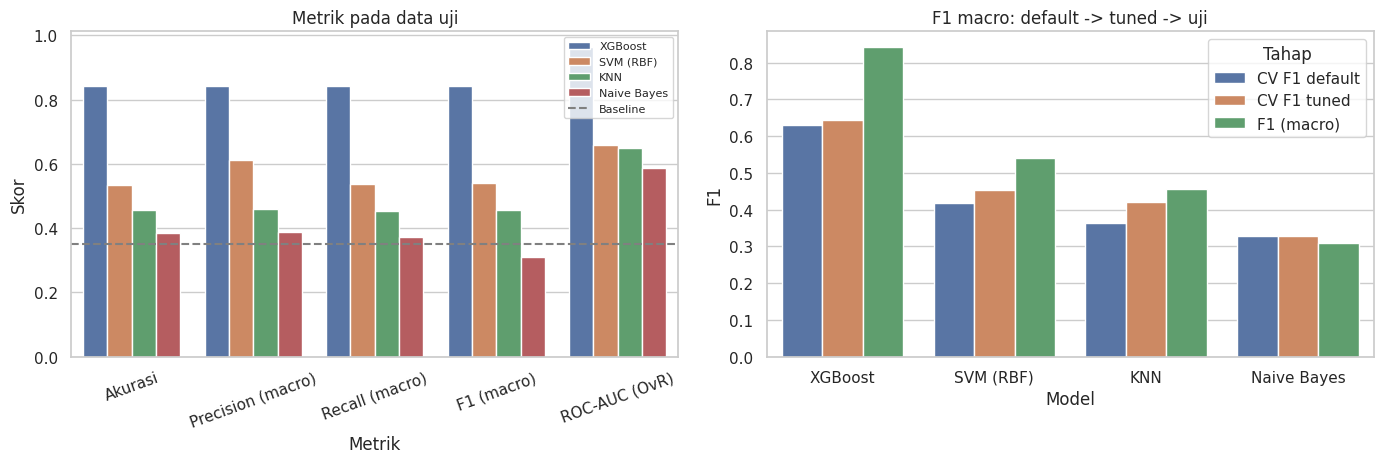

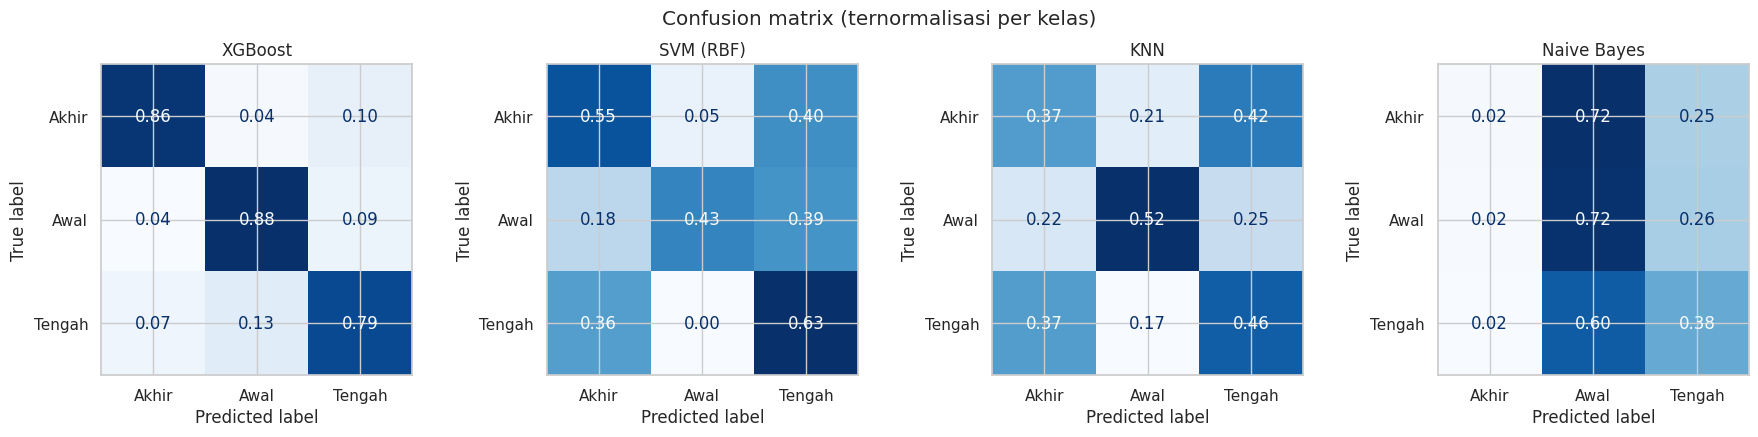

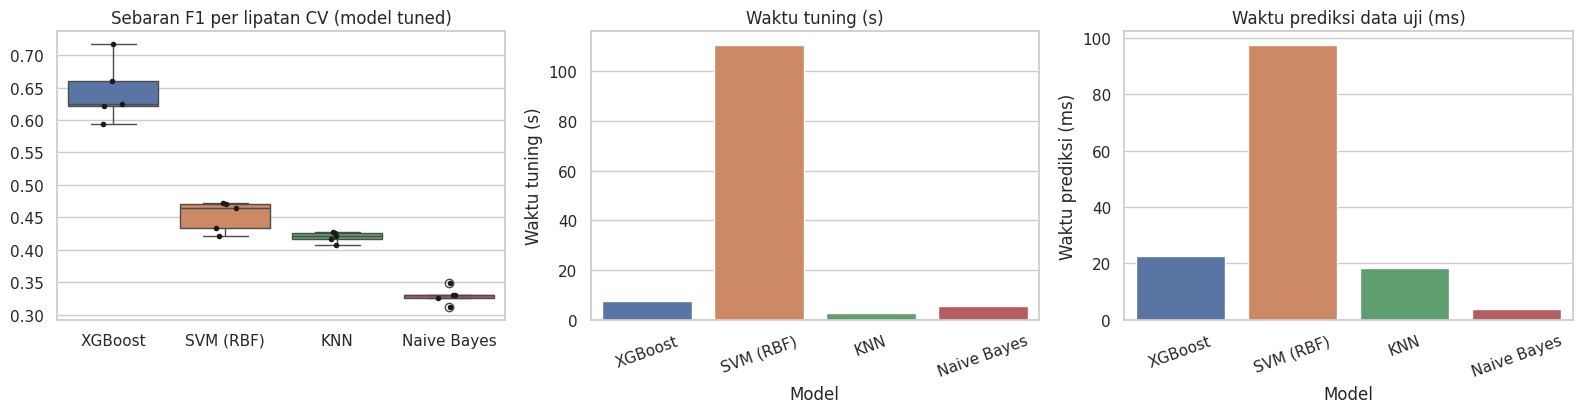

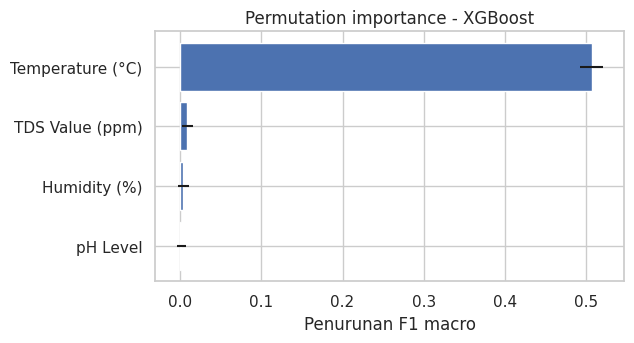

In [23]:
urut = hasil['Model'].tolist(); pal = dict(zip(urut, sns.color_palette('deep', len(urut))))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
M = hasil.melt(id_vars='Model', value_vars=['Akurasi','Precision (macro)','Recall (macro)','F1 (macro)','ROC-AUC (OvR)'], var_name='Metrik', value_name='Skor')
sns.barplot(data=M, x='Metrik', y='Skor', hue='Model', hue_order=urut, ax=ax[0], palette=pal)
ax[0].axhline(BASELINE, color='gray', ls='--', label='Baseline'); ax[0].set_title('Metrik pada data uji'); ax[0].tick_params(axis='x', rotation=20); ax[0].legend(fontsize=8)
T = hasil.melt(id_vars='Model', value_vars=['CV F1 default','CV F1 tuned','F1 (macro)'], var_name='Tahap', value_name='F1')
sns.barplot(data=T, x='Model', y='F1', hue='Tahap', order=urut, ax=ax[1]); ax[1].set_title('F1 macro: default -> tuned -> uji')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(18, 4.3))
for a, nama in zip(ax, urut):
    cm = confusion_matrix(yte, preds[nama], labels=range(len(KELAS)), normalize='true')
    ConfusionMatrixDisplay(cm, display_labels=KELAS).plot(ax=a, colorbar=False, values_format='.2f', cmap='Blues'); a.set_title(nama)
plt.suptitle('Confusion matrix (ternormalisasi per kelas)'); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
cvs = pd.DataFrame({n: cross_val_score(best[n].best_estimator_, Xtr, ytr, cv=CV, groups=gtr, scoring='f1_macro') for n in urut})
sns.boxplot(data=cvs, ax=ax[0], palette=pal); sns.stripplot(data=cvs, ax=ax[0], color='k', size=4); ax[0].set_title('Sebaran F1 per lipatan CV (model tuned)')
sns.barplot(data=hasil, x='Model', y='Waktu tuning (s)', ax=ax[1], palette=pal); ax[1].set_title('Waktu tuning (s)'); ax[1].tick_params(axis='x', rotation=20)
sns.barplot(data=hasil, x='Model', y='Waktu prediksi (ms)', ax=ax[2], palette=pal); ax[2].set_title('Waktu prediksi data uji (ms)'); ax[2].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

top = urut[0]
pi = permutation_importance(best[top].best_estimator_, Xte, yte, scoring='f1_macro', n_repeats=20, random_state=SEED)
s = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
plt.figure(figsize=(6.5, 3.6)); plt.barh(s.index, s.values, xerr=pd.Series(pi.importances_std, index=FEATURES)[s.index].values, color=pal[top])
plt.title(f'Permutation importance - {top}'); plt.xlabel('Penurunan F1 macro'); plt.tight_layout(); plt.show()

## 6. Laporan per kelas & kesimpulan otomatis

In [24]:
for nama in urut:
    print(f'--- {nama} ---'); print(classification_report(yte, preds[nama], target_names=KELAS, digits=4, zero_division=0))
b = hasil.iloc[0]; sel = b['F1 (macro)'] - hasil.iloc[1]['F1 (macro)']
print(f"Model terbaik (F1 macro uji): {b['Model']} | akurasi {b['Akurasi']:.4f}, F1 {b['F1 (macro)']:.4f}, AUC {b['ROC-AUC (OvR)']:.4f} (baseline {BASELINE:.4f}).")
print(f"Selisih dengan peringkat 2 ({hasil.iloc[1]['Model']}): {sel:.4f}", '-> selisih kecil, cek sebaran CV sebelum menyimpulkan.' if sel < 0.02 else '')
print('Catatan: ' + SPLIT_INFO)

--- XGBoost ---
              precision    recall  f1-score   support

       Akhir     0.8818    0.8557    0.8686       305
        Awal     0.8429    0.8780    0.8601       336
      Tengah     0.8065    0.7937    0.8000       315

    accuracy                         0.8431       956
   macro avg     0.8437    0.8425    0.8429       956
weighted avg     0.8433    0.8431    0.8430       956

--- SVM (RBF) ---
              precision    recall  f1-score   support

       Akhir     0.4912    0.5508    0.5193       305
        Awal     0.9057    0.4286    0.5818       336
      Tengah     0.4396    0.6349    0.5195       315

    accuracy                         0.5356       956
   macro avg     0.6121    0.5381    0.5402       956
weighted avg     0.6199    0.5356    0.5413       956

--- KNN ---
              precision    recall  f1-score   support

       Akhir     0.3725    0.3738    0.3732       305
        Awal     0.6027    0.5238    0.5605       336
      Tengah     0.4050    0.